In [2]:
import numpy as np 
import matplotlib.pyplot as plt 

In [10]:
N = 1000 #la cantidad de veces que se corrio 
tiempos_min = np.linspace(5, 50, 10) #5,6,.... minutos

tiempos_seg = tiempos_min * 60
print(tiempos_min)
print(tiempos_seg)


[ 5. 10. 15. 20. 25. 30. 35. 40. 45. 50.]
[ 300.  600.  900. 1200. 1500. 1800. 2100. 2400. 2700. 3000.]


In [20]:
rtf_1ms = 4.45
rtf_5ms = 18
rtf_meta = 10

In [21]:
horas_1ms = N * tiempos_seg / (rtf_1ms*3600)
horas_5ms = N * tiempos_seg / (rtf_5ms*3600)
horas_meta = N * tiempos_seg / (rtf_meta*3600)



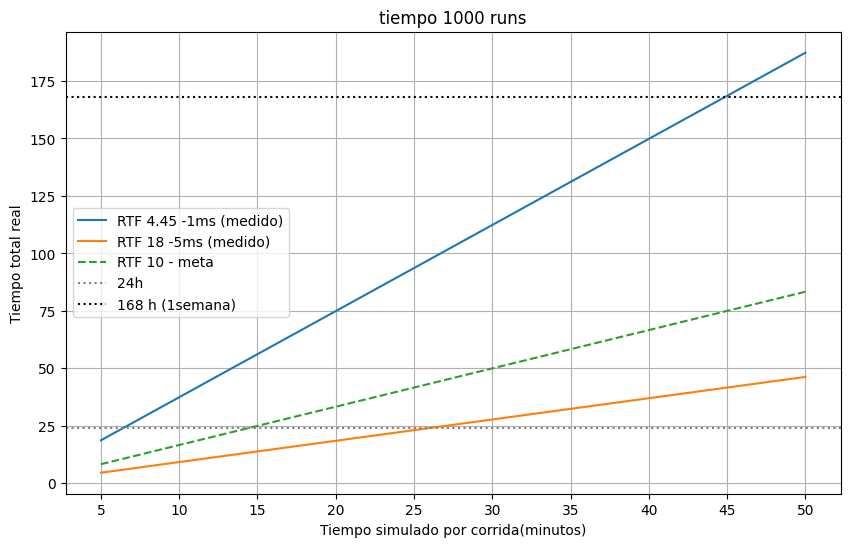

In [22]:
plt.figure(figsize=(10,6))

plt.plot(tiempos_min,horas_1ms,label="RTF 4.45 -1ms (medido)")
plt.plot(tiempos_min,horas_5ms,label="RTF 18 -5ms (medido)")
plt.plot(tiempos_min,horas_meta,"--",label="RTF 10 - meta")

plt.axhline(24,color="gray",linestyle=":", label="24h")
plt.axhline(168, color="black",linestyle=":",label="168 h (1semana)")


plt.title("tiempo 1000 runs")
plt.xlabel("Tiempo simulado por corrida(minutos)")
plt.ylabel("Tiempo total real")
plt.xticks(tiempos_min)
plt.grid(True)
plt.legend()
plt.show()

In [23]:
peor_caso_seg = 3000

horas_1ms_peor = N * peor_caso_seg / (rtf_1ms * 3600)
horas_5ms_peor = N * peor_caso_seg / (rtf_5ms * 3600)
horas_meta_peor = N * peor_caso_seg / (rtf_meta * 3600)

print(f"1 ms, RTF {rtf_1ms}: {horas_1ms_peor:.1f} h")
print(f"5 ms, RTF {rtf_5ms}: {horas_5ms_peor:.1f} h")
print(f"Meta, RTF {rtf_meta}: {horas_meta_peor:.1f} h")

1 ms, RTF 4.45: 187.3 h
5 ms, RTF 18: 46.3 h
Meta, RTF 10: 83.3 h


In [24]:
procesos = np.array([
    "gzserver",
    "zenoh_swarm_bridge",
    "leader_follower_coordinator"
])

cpu_1ms = np.array([115,75,22])
cpu_5ms = np.array([119.7, 131.0,41.7])

costo_1ms = (cpu_1ms/100)/rtf_1ms
costo_5ms = (cpu_5ms/100)/rtf_5ms

print(costo_1ms)
print(costo_5ms)

[0.25842697 0.16853933 0.0494382 ]
[0.0665     0.07277778 0.02316667]


In [26]:
veces_mas_barato = costo_1ms / costo_5ms

tabla = np.column_stack((
    procesos,
    np.char.mod("%.3f",costo_1ms),
    np.char.mod("%.3f",costo_5ms),
    np.char.mod("%.3f", veces_mas_barato)
))

print("Columnas: proceso | costo 1ms | costo 5ms | veces mas barato")
print(tabla)

Columnas: proceso | costo 1ms | costo 5ms | veces mas barato
[['gzserver' '0.258' '0.067' '3.886']
 ['zenoh_swarm_bridge' '0.169' '0.073' '2.316']
 ['leader_follower_coordinator' '0.049' '0.023' '2.134']]


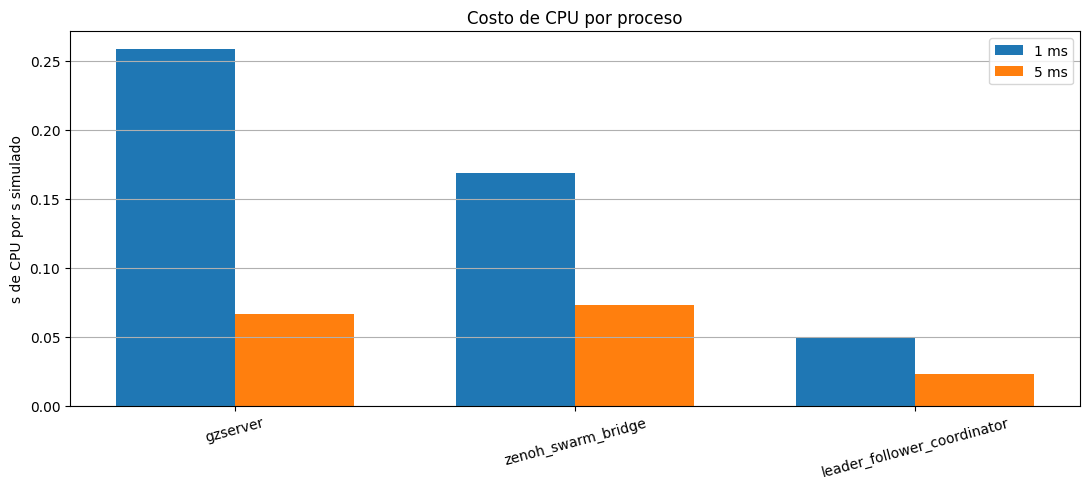

In [27]:
x = np.arange(len(procesos))
ancho = 0.35

plt.figure(figsize=(11, 5))
plt.bar(x - ancho / 2, costo_1ms, ancho, label="1 ms")
plt.bar(x + ancho / 2, costo_5ms, ancho, label="5 ms")

plt.xticks(x, procesos, rotation=15)
plt.ylabel("s de CPU por s simulado")
plt.title("Costo de CPU por proceso")
plt.grid(axis="y")
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
print("Costo gzserver, 1 ms:",
      "OK" if np.isclose(costo_1ms[0], 0.258, atol=0.001) else "FALLA")

print("Peor caso, RTF 18:",
      "OK" if np.isclose(horas_5ms_peor, 46.3, atol=0.05) else "FALLA")

print("Cociente gzserver:",
      "OK" if 3.5 < veces_mas_barato[0] < 4.5 else "FALLA")

Costo gzserver, 1 ms: OK
Peor caso, RTF 18: OK
Cociente gzserver: OK
